# Model 2 v2 – 07 Compare v1 vs v2
**Question:** is v2 better on real-world LEG images without getting worse on the original test set?
**Test sets:** `test` = the same 519 images as v1 (old sources) · `newtest` = held-back new LEG images (other sources,
never trained on). Both versions are scored here with the same code from the v2 cache.
**Decision rule (fixed before looking):** use v2 in the app only if (1) its ensemble HAND/LEG/OTHER accuracy on
`test` is at most 0.5 points lower than v1, (2) it is better on `newtest`, and (3) it routes no more images wrongly.

In [ ]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
V1_DIR, V2_DIR = DRIVE_ROOT / 'outputs' / 'model2', DRIVE_ROOT / 'outputs' / 'model2_v2'
LOW_CONFIDENCE = 0.70                                  # routing rule, as in the app

In [ ]:
!pip install -q timm
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, timm, matplotlib.pyplot as plt
device = 'cuda' if torch.cuda.is_available() else 'cpu'
df = pd.read_csv(V2_DIR / 'manifest_split_v2.csv')
X = np.load(V2_DIR / 'cache_224_v2.npz', allow_pickle=True)['images']
CLASSES = sorted(df.label.unique()); SHORT = {c: c.split(' - ')[0] for c in CLASSES}
SUPER = {c: ('OTHER' if c == 'OTHER' else 'LEG' if SHORT[c] in ('Hip to knee', 'Knee to ankle', 'Foot and ankle') else 'HAND') for c in CLASSES}
S = ['HAND', 'LEG', 'OTHER']; M = np.array([[SUPER[c] == s for s in S] for c in CLASSES], dtype=float)
sets = {s: df[df.split == s].reset_index(drop=True) for s in ['test', 'newtest']}
print({s: len(f) for s, f in sets.items()})

Mounted at /content/drive
{'test': 519, 'newtest': 130}


In [ ]:
from torchvision.models import mobilenet_v3_large
def load_m2(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    if ck.get('timm_name', 'torchvision') == 'torchvision':
        m = mobilenet_v3_large(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, len(ck['classes']))
    else:
        m = timm.create_model(ck['timm_name'], pretrained=False, num_classes=len(ck['classes']))
    m.load_state_dict(ck['state_dict']); return m.eval().to(device), ck['mean'], ck['std'], ck['classes']

@torch.no_grad()
def predict_arr(model, mean, std, arr):
    mean = torch.tensor(mean).view(1, 3, 1, 1).to(device); std = torch.tensor(std).view(1, 3, 1, 1).to(device)
    out = []
    for k in range(0, len(arr), 64):
        t = torch.from_numpy(np.ascontiguousarray(arr[k:k+64])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.softmax(model((t - mean) / std), 1).cpu().numpy())
    return np.concatenate(out)

P = {}
for v, d, tag in [('v1', V1_DIR, 'model2'), ('v2', V2_DIR, 'model2v2')]:
    for name in ['mobilenetv3', 'deit_small']:
        m, mean, std, cls = load_m2(d / f'{name}_{tag}_best.pt'); assert list(cls) == CLASSES
        for s, f in sets.items(): P[(v, name, s)] = predict_arr(m, mean, std, X[f.cache_idx.values])
    for s in sets: P[(v, 'ensemble', s)] = (P[(v, 'mobilenetv3', s)] + P[(v, 'deit_small', s)]) / 2
print('Predicted', len(P), 'model/test combinations')

Predicted 12 model/test combinations


## Step 1 – Accuracy, LEG recall and the routing rule

In [ ]:
from sklearn.metrics import f1_score
rows = []
for s, f in sets.items():
    ts = f.label.map(SUPER).values; y7 = f.label.map({c: i for i, c in enumerate(CLASSES)}).values
    for v in ['v1', 'v2']:
        for name in ['mobilenetv3', 'deit_small', 'ensemble']:
            p = P[(v, name, s)]; ps = p @ M; pred = np.array(S)[ps.argmax(1)]; ok = pred == ts
            row = {'set': s, 'version': v, 'model': name, 'acc_3': ok.mean(), 'LEG_correct': ok[ts == 'LEG'].mean(),
                   'HAND_correct': ok[ts == 'HAND'].mean() if (ts == 'HAND').any() else np.nan,
                   'acc_7': (p.argmax(1) == y7).mean()}
            if name == 'ensemble':
                a = np.array(S)[(P[(v, 'mobilenetv3', s)] @ M).argmax(1)]; b = np.array(S)[(P[(v, 'deit_small', s)] @ M).argmax(1)]
                routed = (a == b) & (ps.max(1) >= LOW_CONFIDENCE)
                row.update(routed=routed.mean(), wrongly_routed=int((routed & ~ok).sum()), to_review=int((~routed).sum()),
                           disagree=int((a != b).sum()))
            rows.append(row)
res = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(res.round(3).to_string(index=False))
res.round(4).to_csv(V2_DIR / 'compare_v1_vs_v2.csv', index=False)

    set version       model  acc_3  LEG_correct  HAND_correct  acc_7  routed  wrongly_routed  to_review  disagree
   test      v1 mobilenetv3  0.973        0.943         0.989  0.915     NaN             NaN        NaN       NaN
   test      v1  deit_small  0.985        0.966         0.994  0.936     NaN             NaN        NaN       NaN
   test      v1    ensemble  0.987        0.966         0.997  0.929   0.975             4.0       13.0      12.0
   test      v2 mobilenetv3  0.979        0.954         0.997  0.923     NaN             NaN        NaN       NaN
   test      v2  deit_small  0.979        0.954         0.983  0.919     NaN             NaN        NaN       NaN
   test      v2    ensemble  0.987        0.966         0.994  0.929   0.961             1.0       20.0      18.0
newtest      v1 mobilenetv3  0.662        0.662           NaN  0.562     NaN             NaN        NaN       NaN
newtest      v1  deit_small  0.946        0.946           NaN  0.915     NaN            

In [ ]:
e = res[res.model == 'ensemble'].set_index(['set', 'version'])
c1 = e.loc[('test', 'v2'), 'acc_3'] >= e.loc[('test', 'v1'), 'acc_3'] - 0.005
c2 = e.loc[('newtest', 'v2'), 'acc_3'] > e.loc[('newtest', 'v1'), 'acc_3']
c3 = (e.loc[('test', 'v2'), 'wrongly_routed'] + e.loc[('newtest', 'v2'), 'wrongly_routed']) <= \
     (e.loc[('test', 'v1'), 'wrongly_routed'] + e.loc[('newtest', 'v1'), 'wrongly_routed'])
print(f'(1) old test not worse (max -0.5 pt): {c1}\n(2) better on new LEG test: {c2}\n(3) not more wrongly routed: {c3}')
print('\nDECISION:', 'USE v2 in the app' if c1 and c2 and c3 else 'KEEP v1 (report v2 as an experiment)')

(1) old test not worse (max -0.5 pt): True
(2) better on new LEG test: True
(3) not more wrongly routed: True

DECISION: USE v2 in the app


## Step 2 – New LEG test: which images changed (v1 → v2 ensemble)

Per source, % called LEG:
             v1     v2
source                
L_leg     0.927  0.964
knee      0.967  1.000
teammate  0.867  1.000
L37.png [['LEG', 'LEG']]
L120.png [['LEG', 'LEG']]

Still wrong with v2: 2


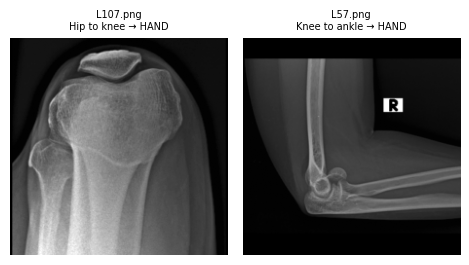

In [ ]:
f = sets['newtest']; pv1 = np.array(S)[(P[('v1', 'ensemble', 'newtest')] @ M).argmax(1)]
pv2 = np.array(S)[(P[('v2', 'ensemble', 'newtest')] @ M).argmax(1)]
t = pd.DataFrame({'file': f.filename, 'source': f.source, 'region': f.label.map(SHORT), 'v1': pv1, 'v2': pv2})
print('Per source, % called LEG:'); print(t.groupby('source')[['v1', 'v2']].agg(lambda s: (s == 'LEG').mean()).round(3).to_string())
for fn in ['L37.png', 'L120.png']:
    if (t.file == fn).any(): print(fn, t[t.file == fn][['v1', 'v2']].values.tolist())
still = t[t.v2 != 'LEG']
print('\nStill wrong with v2:', len(still))
if len(still):
    show = still.head(12)
    fig, axes = plt.subplots(1, len(show), figsize=(2.4 * len(show), 3)); axes = np.atleast_1d(axes)
    for ax, (i, r) in zip(axes, show.iterrows()):
        ax.imshow(X[f.cache_idx[i]], cmap='gray'); ax.axis('off'); ax.set_title(f'{r.file[:14]}\n{r.region} → {r.v2}', fontsize=7)
    plt.tight_layout(); plt.show()

## Summary – Model 2 v1 vs v2 (decision rule fixed in advance: USE v2)
| | v1 ensemble | v2 ensemble |
|---|---|---|
| Old test (519) HAND/LEG/OTHER correct | 98.7% | 98.7% |
| Old test wrongly routed / sent to review | 4 / 13 | 1 / 20 |
| New LEG test (130, held back) correct | 93.8% | 98.5% |
| New LEG test routed automatically / wrongly routed | 67.7% / 5 | 99.2% / 2 |
Cause confirmed: v1 MobileNetV3 called only 66.2% of new LEG images LEG (HAND bias); v2 MobileNetV3 97.7%.
Per source called LEG (v1 → v2): L* 92.7 → 96.4%, knees 96.7 → 100%, team images 86.7 → 100%. L37, L120 now LEG.
Remaining: L107 (axial patella view, rare projection) → HAND; L57 is an ELBOW mislabelled in the L* folder (v2 correct).

Mounted at /content/drive


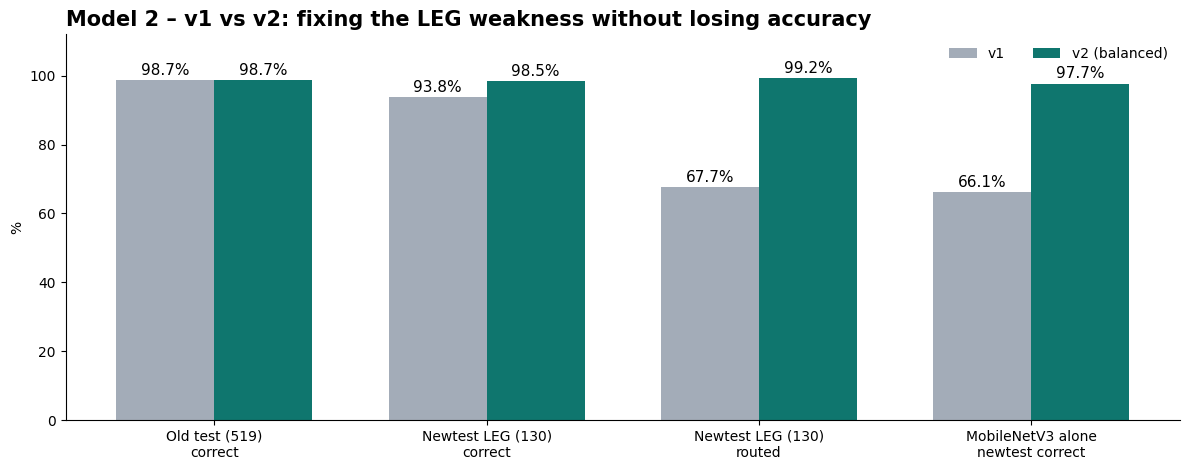

Saved to Drive: /content/drive/MyDrive/Research/outputs/model2_v2/chart_model2_v1_vs_v2.png


In [1]:
# ===== Step 3 – Chart for the presentation (reads the saved results, no models needed) =====
from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt

V2_DIR = Path('/content/drive/MyDrive/Research/outputs/model2_v2')
res = pd.read_csv(V2_DIR / 'compare_v1_vs_v2.csv')
g = lambda s, v, m, col: res[(res.set == s) & (res.version == v) & (res.model == m)][col].iloc[0] * 100

groups = ['Old test (519)\ncorrect', 'Newtest LEG (130)\ncorrect', 'Newtest LEG (130)\nrouted', 'MobileNetV3 alone\nnewtest correct']
vals = {v: [g('test', v, 'ensemble', 'acc_3'), g('newtest', v, 'ensemble', 'acc_3'),
            g('newtest', v, 'ensemble', 'routed'), g('newtest', v, 'mobilenetv3', 'acc_3')] for v in ['v1', 'v2']}

x, w = np.arange(4), 0.36
fig, ax = plt.subplots(figsize=(12, 4.8))
b1 = ax.bar(x - w/2, vals['v1'], w, color='#A3ACB8', label='v1')
b2 = ax.bar(x + w/2, vals['v2'], w, color='#0F766E', label='v2 (balanced)')
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 1.5, f'{r.get_height():.1f}%', ha='center', fontsize=11)
ax.set_xticks(x); ax.set_xticklabels(groups); ax.set_ylim(0, 112); ax.set_ylabel('%')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, ncol=2, loc='upper right')
ax.set_title('Model 2 – v1 vs v2: fixing the LEG weakness without losing accuracy', loc='left', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(V2_DIR / 'chart_model2_v1_vs_v2.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved to Drive:', V2_DIR / 'chart_model2_v1_vs_v2.png')